# Bank Term Deposit Prediction

**Midterm project — DataTalksClub Machine Learning Zoomcamp**

## The business problem

A Portuguese bank sells *term deposits* (fixed-term savings products) through
phone marketing campaigns. An agent calls clients one by one and tries to
persuade them to subscribe. Calling is expensive: agent time is limited, and
clients who are repeatedly called about a product they do not want get annoyed
and may leave the bank.

So the bank does not actually want to call *everyone*. It wants to call the
**right** people first. That is exactly what a classifier can help with:

> Given what we know about a client *before* the campaign call (their profile,
> their account, and their history with previous campaigns), predict the
> probability that this client will subscribe to a term deposit — then rank
> the call list by that probability and spend the agents' time from the top
> of the list down.

**What success looks like.** Not "the model is 88% accurate" — with this data
that number is almost meaningless (Section 4 explains why). Success is:
*the top slice of the ranked list contains a much higher concentration of
subscribers than the raw client base*, so the same number of calls produces
more subscriptions.

## The data

The [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)
(`bank-full.csv`, Moro et al., 2014) contains 45,211 clients contacted in
campaigns run between May 2008 and November 2010, with 16 input features and
one target:

- `y` = `yes` if the client subscribed to a term deposit, `no` otherwise.

The features fall into four groups:

| Group | Features |
|---|---|
| Client profile | `age`, `job`, `marital`, `education` |
| Account / credit | `default` (has credit in default), `balance` (avg. yearly balance, EUR), `housing` (has housing loan), `loan` (has personal loan) |
| Campaign contact | `contact` (phone type), `day`, `month` (of last contact), `duration` (length of last call, seconds) |
| Previous campaigns | `campaign` (contacts in *this* campaign), `pdays` (days since previous campaign contact, −1 = never), `previous` (number of previous contacts), `poutcome` (outcome of the previous campaign) |

## Roadmap of this notebook

1. Load the data and prepare it (types, the `unknown` category, target encoding).
2. Exploratory data analysis (EDA) — understand each feature and its relation
   to the target, including feature-importance estimates.
3. Confront a data-leakage trap hidden in the features (`duration`) and decide
   what the honest, deployable model may use.
4. Split into train / validation / test and encode features for the models.
5. Train four model families, tune their hyperparameters on the validation set.
6. Retrain the winner on train+validation, evaluate **once** on the test set,
   and translate the scores into a business decision (who to call first).

## 1. Loading the data

We load the raw CSV exactly as UCI ships it. Two details matter:

- The separator is a **semicolon** (`;`), not a comma — a very common gotcha
  with European datasets. If you forget it, pandas happily loads the file as a
  single giant column.
- We load *everything as-is* first and inspect before touching anything.
  Cleaning decisions should be based on what the data actually contains, not
  on assumptions.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('data/bank-full.csv', sep=';')

print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Shape: 45,211 rows x 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
# One row per client contact record; check the column types pandas inferred
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

**What we see.** 45,211 rows and 17 columns (16 features + target `y`), exactly
as documented. The numeric columns (`age`, `balance`, `day`, `duration`,
`campaign`, `pdays`, `previous`) were inferred as integers, and everything
else as text (`object`). No parsing errors, so we can move to preparation.

## 2. Data preparation and cleaning

"Cleaning" this dataset is mostly about *understanding* three quirks rather
than fixing broken values:

1. **There are no true missing values** (no `NaN`s) — but several categorical
   columns use the string `'unknown'` (e.g. in `job`, `education`, `contact`,
   `poutcome`). That is the bank saying "we don't know", which is **not** the
   same as a broken record.
2. **`pdays = -1` is a code, not a measurement.** It means "this client was
   never contacted in a previous campaign". We keep it as-is: tree models
   handle an out-of-range sentinel naturally, and the group it identifies
   (never contacted before) is a real, meaningful segment.
3. **The target is text** (`yes`/`no`); scikit-learn models want numbers, so
   we map it to 1/0.

### Why we keep `'unknown'` as its own category

The tempting move is to treat `'unknown'` as missing and impute it (fill with
the most common value) or drop those rows. Both are bad here:

- Dropping rows would delete a large share of the data (for `poutcome`,
  roughly 4 out of 5 rows are `'unknown'`, because most clients were never in
  a previous campaign) and would bias the sample toward previously-contacted
  clients.
- Imputing pretends we know something we don't, and destroys real signal:
  e.g. clients whose `contact` is `'unknown'` behave *differently* from
  cellular- or telephone-contacted clients, as the EDA will show.

One-hot encoding (Section 5) turns `'unknown'` into just another category
column, which is exactly the honest treatment.

In [3]:
# Are there any true missing values?
print('True NaN count per column:')
print(df.isna().sum().to_string())

True NaN count per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0


In [4]:
# How common is the 'unknown' category in each categorical column?
cat_columns = ['job', 'marital', 'education', 'default',
               'housing', 'loan', 'contact', 'month', 'poutcome']

for col in cat_columns:
    share = (df[col] == 'unknown').mean()
    print(f'{col:10s} unknown: {share:6.1%}')

job        unknown:   0.6%
marital    unknown:   0.0%
education  unknown:   4.1%
default    unknown:   0.0%
housing    unknown:   0.0%
loan       unknown:   0.0%
contact    unknown:  28.8%
month      unknown:   0.0%
poutcome   unknown:  81.7%


In [5]:
# Check for fully duplicated rows (there should be none in bank-full)
print(f'Duplicated rows: {df.duplicated().sum()}')

Duplicated rows: 0


In [6]:
# Encode the target: yes -> 1 (subscribed), no -> 0
df['y'] = (df['y'] == 'yes').astype(int)

print('Target value counts:')
print(df['y'].value_counts())
print(f"\nPositive rate: {df['y'].mean():.1%}")

Target value counts:
y
0    39922
1     5289
Name: count, dtype: int64

Positive rate: 11.7%


**What we see.** No `NaN`s anywhere and no duplicated rows, so the data is
structurally clean. The `'unknown'` shares confirm the point above: `poutcome`
is unknown for ~82% of clients (most were never in an earlier campaign) and
`contact` for ~29% — far too much to throw away.

The target is **imbalanced**: only about **11.7%** of clients subscribed.
Keep that number in mind — it drives the choice of evaluation metric in the
next section.

## 3. Exploratory data analysis (EDA)

EDA is not decoration. Every plot below answers a question that later affects
a modelling decision: which features carry signal, which are noisy, which are
suspicious, and how the target behaves.

### 3.1 The target: why accuracy is the wrong metric here

Start with the simplest possible "model": predict that *nobody* subscribes.
With an 11.7% positive rate, that lazy model is right 88.3% of the time! Any
real model reporting "accuracy ≈ 89%" may have learned literally nothing.

That is why this project evaluates models with **ROC AUC** instead:

- A model outputs a *probability* of subscribing for each client.
- **ROC AUC** answers: "pick one random subscriber and one random
  non-subscriber — what is the probability the model scored the subscriber
  higher?" It is 0.5 for random guessing and 1.0 for a perfect ranker.
- Crucially, ROC AUC measures **ranking quality**, which is exactly the
  business task (rank the call list), and it does not collapse under class
  imbalance the way accuracy does.

We will still look at precision/recall at concrete thresholds in Section 9,
because the bank ultimately has to decide *where to stop calling*.

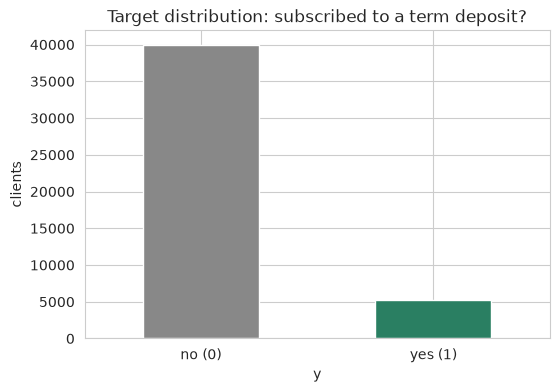

Baseline 'predict nobody subscribes' accuracy: 88.3%


In [7]:
plt.figure(figsize=(6, 4))
df['y'].value_counts().sort_index().plot(kind='bar', color=['#888888', '#2a7f62'])
plt.xticks([0, 1], ['no (0)', 'yes (1)'], rotation=0)
plt.ylabel('clients')
plt.title('Target distribution: subscribed to a term deposit?')
plt.show()

print(f"Baseline 'predict nobody subscribes' accuracy: {(df['y'] == 0).mean():.1%}")

**What we see.** The imbalance is stark: ~39,900 non-subscribers vs ~5,300
subscribers. From here on, every model comparison uses ROC AUC, and every
"accuracy-like" number will be judged against the 88.3% do-nothing baseline.

### 3.2 Numeric features: distributions

Before relating features to the target, look at each numeric feature on its
own. We are hunting for three things: **outliers** (values so extreme they may
be data errors or dominate a model), **skew** (long tails), and **sentinel
codes** (like `pdays = -1`) hiding inside an otherwise numeric column.

In [8]:
num_columns = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

df[num_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


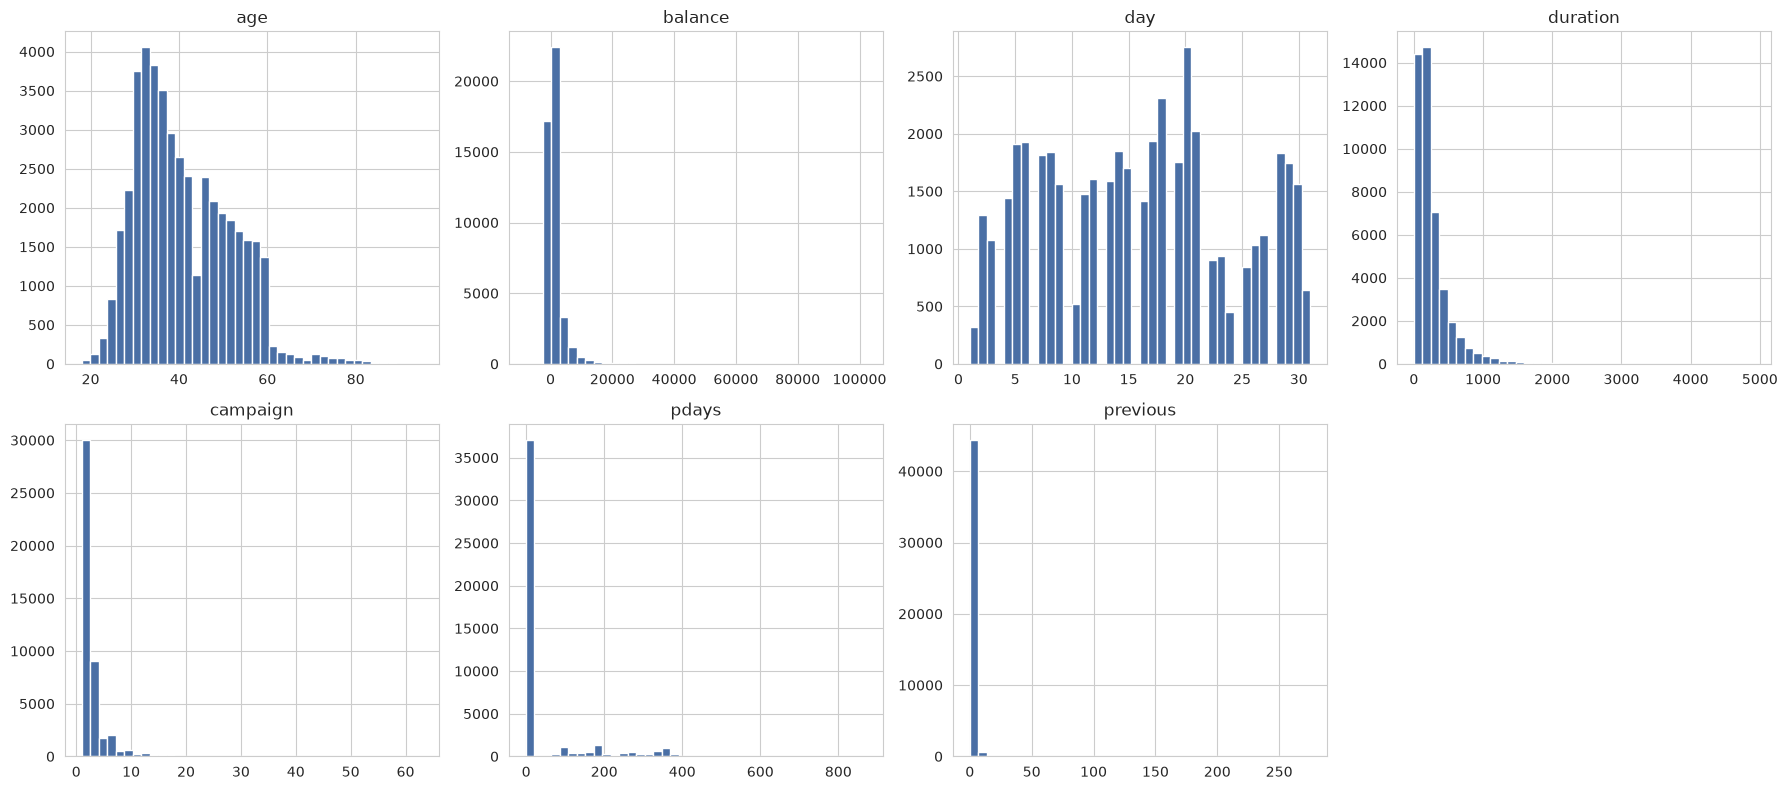

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_columns):
    df[col].hist(ax=ax, bins=40, color='#4a6fa5')
    ax.set_title(col)
# hide the unused 8th subplot
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**What we see.**

- **`balance`** is heavily right-skewed: the median client holds just
  448 EUR and the middle half sits between 72 and 1,428 EUR, yet a few hold
  tens of thousands (max ≈ 102,000). It also goes *negative* (overdrawn
  accounts, min ≈ −8,000). Tree models do not care about skew; logistic
  regression does a bit — one reason to try both.
- **`pdays`** has a huge spike at **−1** (never previously contacted) and a long
  tail out to ~870 days. It is really a categorical fact ("contacted before?")
  wearing a numeric costume.
- **`duration`** (seconds) is right-skewed too: most calls are short, a few run
  past 20 minutes. Remember this column — Section 3.6 shows why it is a trap.
- **`campaign`** (contacts in this campaign) is concentrated at 1–3 with a long
  tail; some clients were called 60+ times, which smells like desperation
  rather than a winning strategy (see the target relation below).
- **`age`** looks almost normal (mean ≈ 41), spanning 18–95, no crazy outliers.

### 3.3 Numeric features vs the target

Averages by target class are a quick first look at signal: if subscribers and
non-subscribers have very different means for a feature, that feature probably
helps the model.

In [10]:
df.groupby('y')[num_columns].mean().T.round(1)

y,0,1
age,40.8,41.7
balance,1303.7,1804.3
day,15.9,15.2
duration,221.2,537.3
campaign,2.8,2.1
pdays,36.4,68.7
previous,0.5,1.2


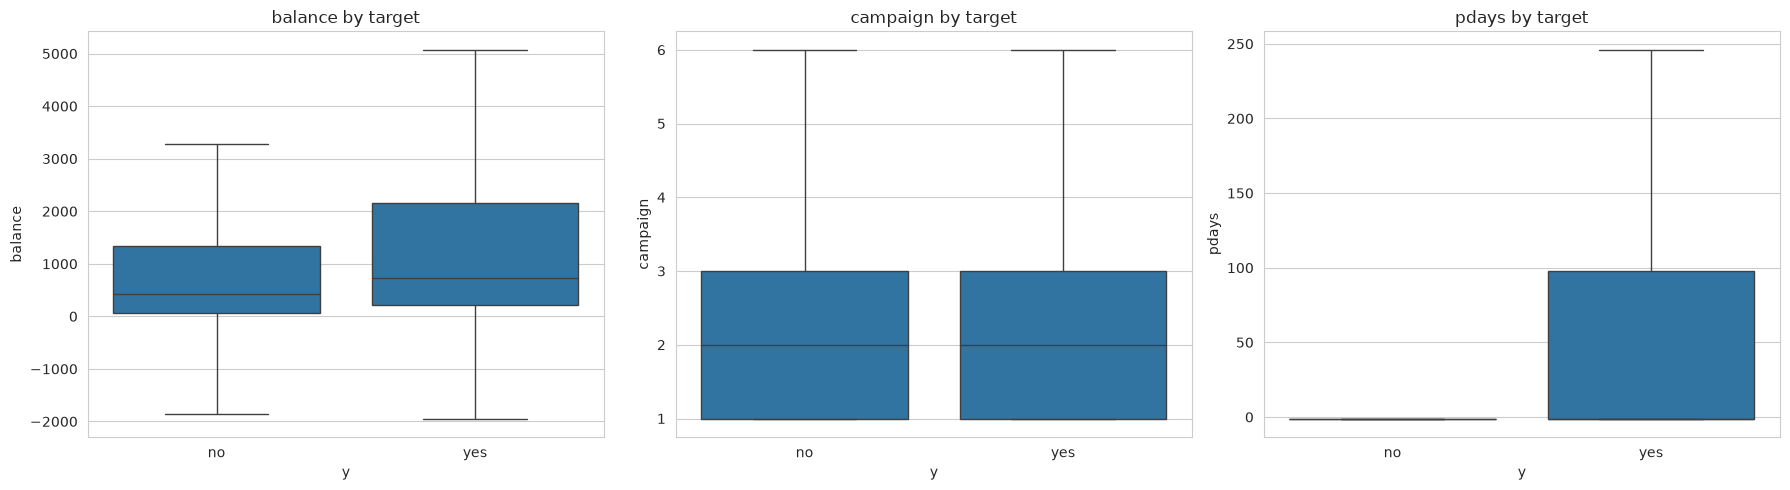

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['balance', 'campaign', 'pdays']):
    sns.boxplot(data=df, x='y', y=col, ax=ax, showfliers=False)
    ax.set_title(f'{col} by target')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['no', 'yes'])
plt.tight_layout()
plt.show()

**What we see.**

- Subscribers have a noticeably **higher average balance** (≈1,800 vs ≈1,300
  EUR): clients with more money at the bank are more likely to lock some of it
  into a term deposit. Plausible, and useful signal.
- Subscribers were called **fewer times** in this campaign (`campaign` ≈ 2.1
  vs ≈ 2.8). More calls do *not* create subscriptions — if anything, the clients
  who need 10 calls mostly say no in the end. This is partly reverse causality:
  agents keep retrying the reluctant ones.
- `pdays` and `previous` *do* differ: subscribers average 68.7 days since
  their previous contact vs 36.4, and 1.2 previous contacts vs 0.5. But read
  the medians, not just the means — for both groups the median client was
  never contacted before (pdays = −1, previous = 0), so the whole effect is
  produced by the previously-contacted minority. The `poutcome` analysis
  below isolates that minority much more cleanly.

### 3.4 Categorical features vs the target

For each categorical feature we plot the **subscription rate within each
category**. A feature is useful if its categories have very different rates —
that spread is exactly what a model exploits. (The dashed line is the overall
11.7% base rate.)

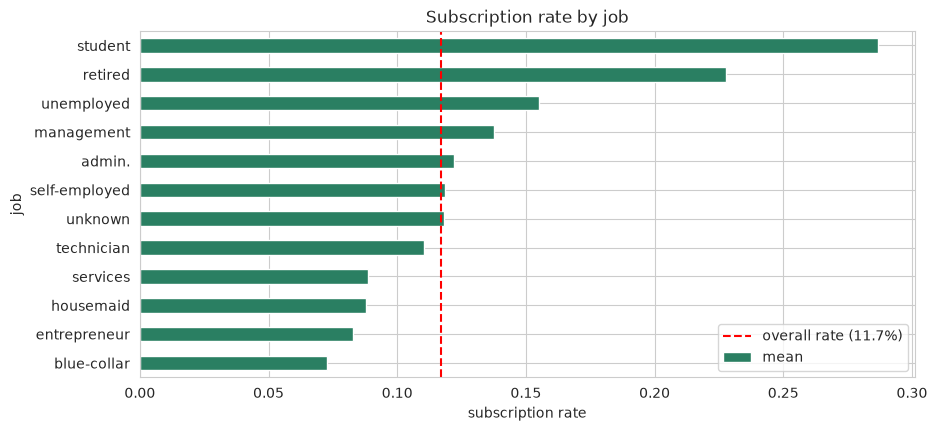

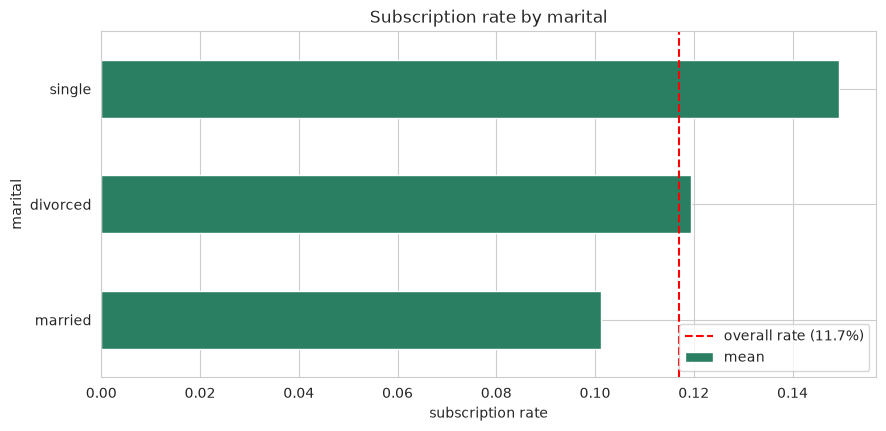

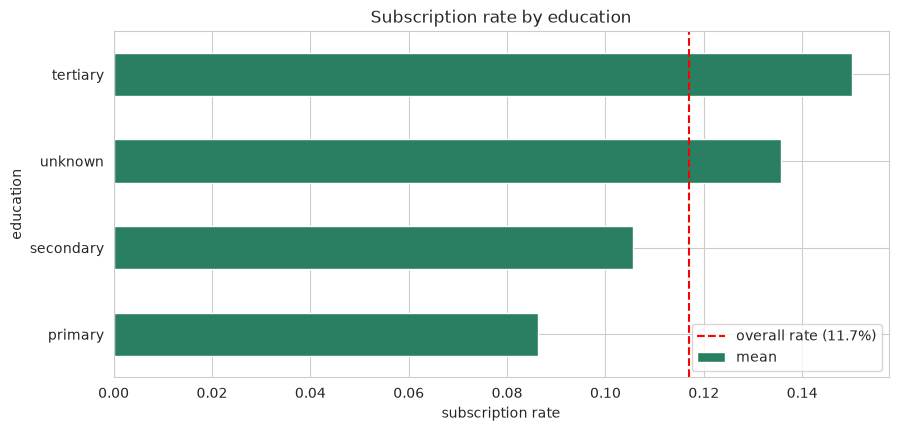

In [12]:
def rate_plot(col, figsize=(10, 4.5), min_count=100):
    stats = df.groupby(col)['y'].agg(['mean', 'count']).sort_values('mean')
    stats = stats[stats['count'] >= min_count]
    plt.figure(figsize=figsize)
    stats['mean'].plot(kind='barh', color='#2a7f62')
    plt.axvline(df['y'].mean(), color='red', linestyle='--', label='overall rate (11.7%)')
    plt.xlabel('subscription rate')
    plt.title(f'Subscription rate by {col}')
    plt.legend()
    plt.show()

rate_plot('job')
rate_plot('marital')
rate_plot('education')

**What we see.**

- **`job`**: students (28.7%) and retired clients (22.8%) subscribe at
  roughly 2–2.5× the base rate — students may have time to listen and small
  sums to place; retired clients hold savings they want to put to work. At
  the bottom sit blue-collar clients (7.3%) and entrepreneurs (8.3%); the
  `unknown`-job group is mid-pack (11.8%), so here missingness itself is not
  the bad sign it is elsewhere.
- **`marital`**: singles subscribe most (14.9%), then divorced clients
  (11.9%), then married clients (10.1%) — a modest but consistent spread.
- **`education`**: mostly a gradient — tertiary (15.0%) > secondary (10.6%)
  > primary (8.6%) — with `unknown` education oddly second (13.6%). That
  group is small (~4% of clients), so we note the anomaly and move on rather
  than building a story on it.

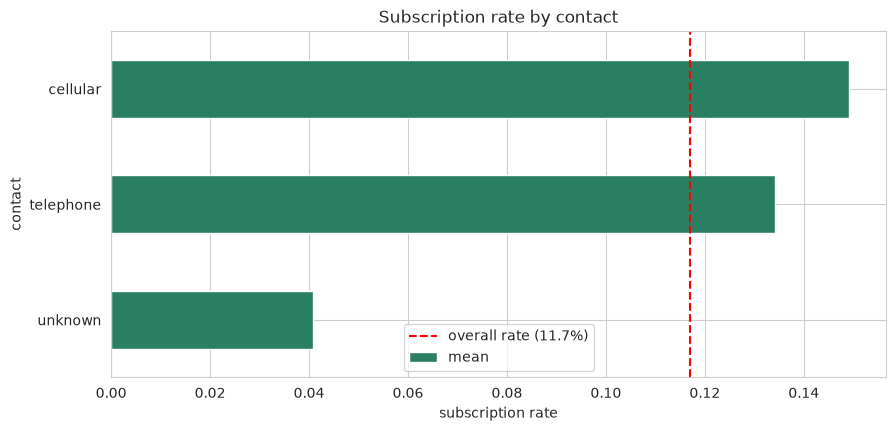

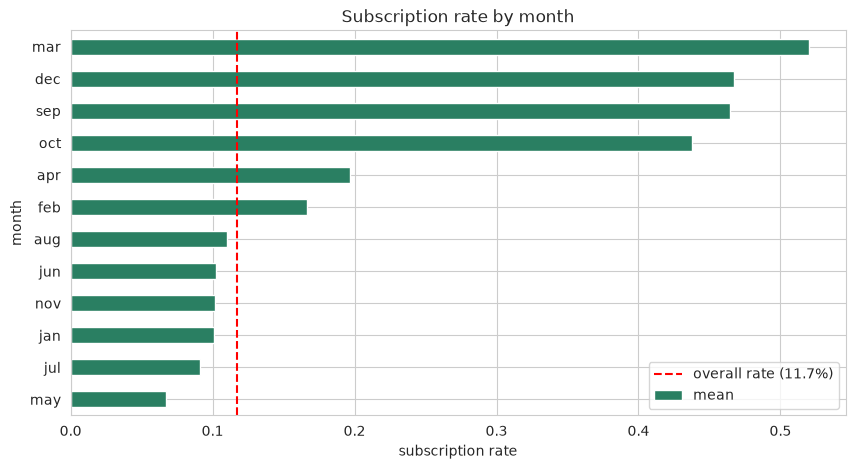

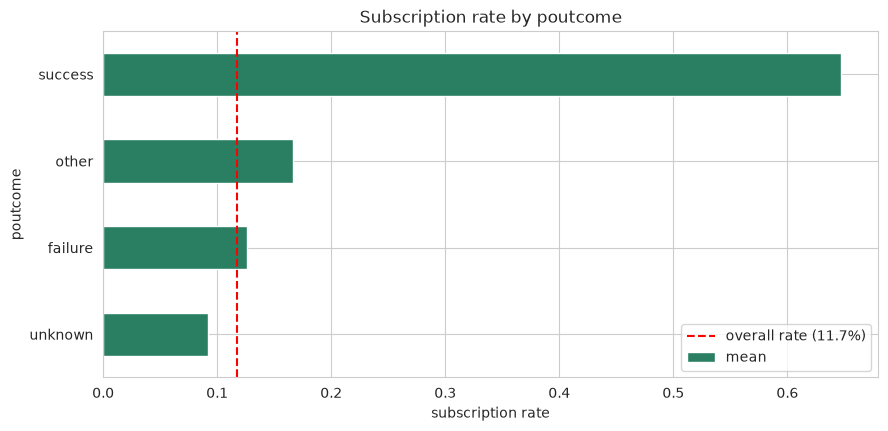

In [13]:
rate_plot('contact')
rate_plot('month', figsize=(10, 5))
rate_plot('poutcome')

**What we see.**

- **`contact`**: cellular converts a bit better than telephone (14.9% vs
  13.4%), but the real story is `unknown` contact at just 4.1% — clients the
  bank could not properly reach almost never subscribe. Reachability *is*
  signal.
- **`month`**: dramatic seasonality. March (52.0%), December (46.7%),
  September (46.5%) and October (43.8%) convert at 4–8× the rate of May
  (6.7%) — the biggest calling month and the worst converting. The small
  months look like carefully targeted mini-campaigns; May looks like a blast
  at the whole client base.
- **`poutcome`** is the single loudest categorical feature in the dataset:
  clients whose *previous* campaign ended in **`success` subscribe 64.7% of
  the time** — more than 5× the base rate. A past yes is a powerful
  predictor of a future yes. `other` outcomes (16.7%) also convert above the
  base rate, `failure` (12.6%) sits right at it, and the huge `unknown`
  group (never campaigned before) sits below it at 9.2%.

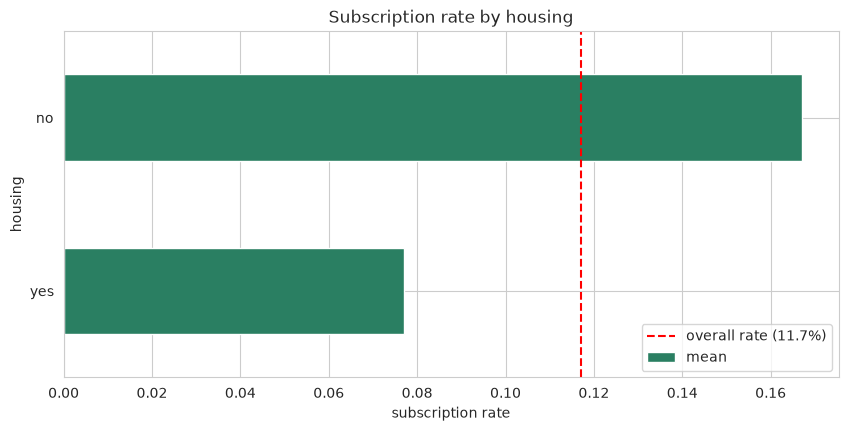

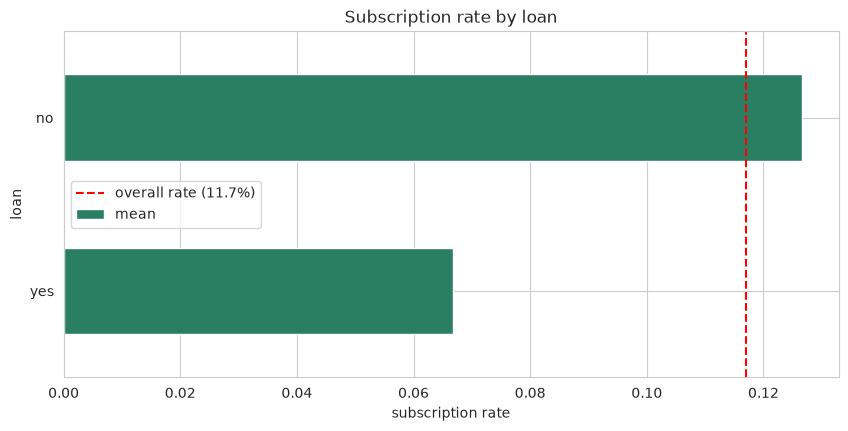

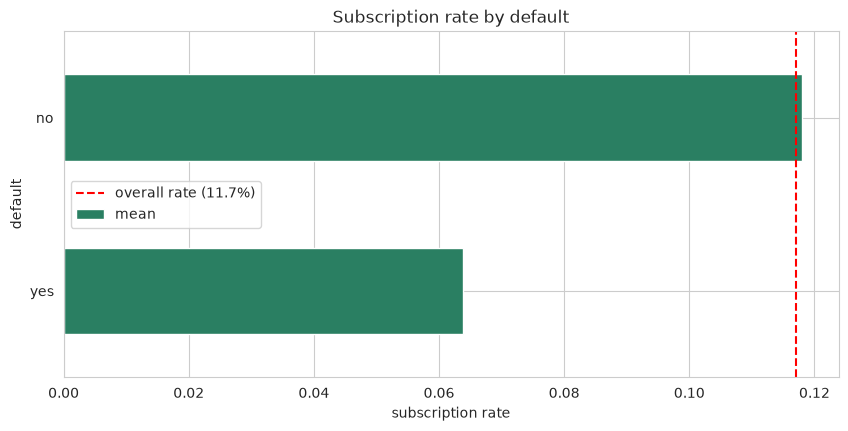

In [14]:
rate_plot('housing')
rate_plot('loan')
rate_plot('default')

**What we see.** Debt is a strong negative signal: clients with a
**housing loan subscribe at 7.7% vs 16.7%** for those without one, and a
personal loan roughly halves the rate too (6.7% vs 12.7%). Clients with a
credit default subscribe *less* (6.4% vs 11.8%), but that group is tiny
(1.8% of clients), so the estimate is noisy and the model will rightly not
lean on it much. Intuition: clients already servicing debt have less spare
cash to lock into a deposit.

### 3.5 Correlations between numeric features

The correlation heatmap checks whether numeric features duplicate each other
(redundant features are not harmful for trees, but worth knowing about) and
gives a first linear view of each feature's relation to the target.

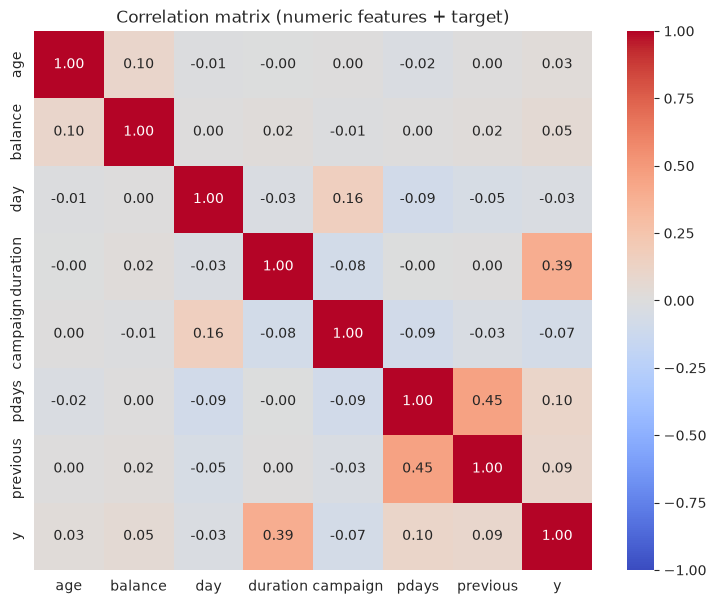

In [15]:
plt.figure(figsize=(9, 7))
corr = df[num_columns + ['y']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (numeric features + target)')
plt.show()

**What we see.**

- Almost all pairwise correlations are weak — good news: the features mostly
  carry *different* information.
- The strongest pair is `pdays` ↔ `previous` (≈0.45): unsurprising, both
  describe contact history (if you were contacted before, both are non-trivial).
- Against the target, `duration` has the highest linear correlation (≈0.39) —
  far above everything else (`balance` ≈0.05, `campaign` ≈−0.07). A feature
  that towers over all others like this deserves suspicion, not celebration.
  Next section explains why.

### 3.6 The `duration` trap: target leakage

**Target leakage** means a feature secretly contains information about the
target that would **not be available at prediction time**. Models trained on
leaked features look brilliant in evaluation and fail in production.

`duration` is the length of the *final campaign call* — the very call during
which the client decides. The UCI paper itself warns:

> "duration is not known before a call is performed" and "if duration = 0
> then y = no".

Think about what the bank needs: a ranked call list **before** dialling. At
that moment, the duration of a call that hasn't happened yet is unknowable.
A model using `duration` answers the wrong question ("given that we already
talked to them for 5 minutes, will they subscribe?") instead of the right
one ("whom should we call?"). Worse, the causal arrow points backwards:
calls are long *because* the client is interested and signing up.

Let's look at how extreme the effect is, then quantify it in the modelling
section by training the same model with and without `duration`.

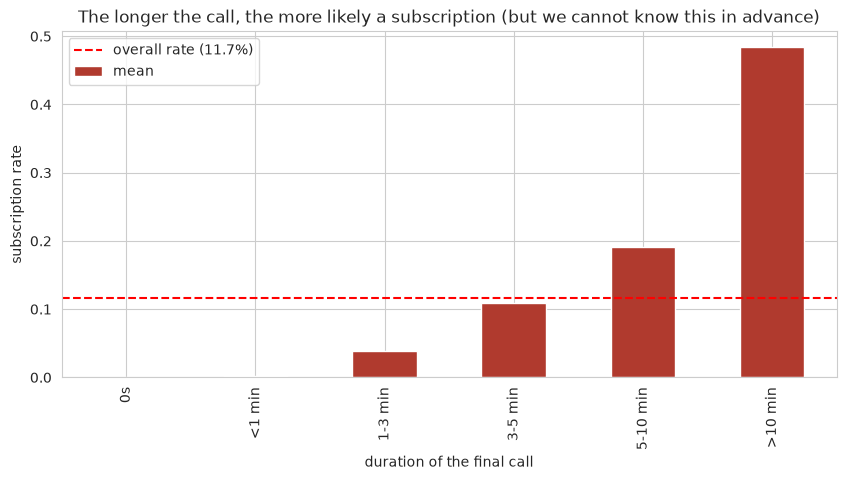

           mean  count
duration              
0s        0.000      3
<1 min    0.002   4763
1-3 min   0.039  17894
3-5 min   0.109  10277
5-10 min  0.192   8484
>10 min   0.484   3790


In [16]:
# Subscription rate by duration bucket (minutes)
buckets = pd.cut(df['duration'], bins=[-1, 0, 60, 180, 300, 600, 5000],
                 labels=['0s', '<1 min', '1-3 min', '3-5 min', '5-10 min', '>10 min'])
dur_stats = df.groupby(buckets, observed=True)['y'].agg(['mean', 'count'])

plt.figure(figsize=(10, 4.5))
dur_stats['mean'].plot(kind='bar', color='#b03a2e')
plt.axhline(df['y'].mean(), color='red', linestyle='--', label='overall rate (11.7%)')
plt.ylabel('subscription rate')
plt.xlabel('duration of the final call')
plt.title('The longer the call, the more likely a subscription (but we cannot know this in advance)')
plt.legend()
plt.show()

print(dur_stats.round(3).to_string())

**What we see.** The relationship is dramatic: calls of **0 seconds
convert at exactly 0%** (only 3 such rows, but the logic is airtight — no
conversation, no subscription; the leak in its purest form). From there the
rate climbs relentlessly: under a minute 0.2%, 1–3 minutes 3.9%, 3–5
minutes 10.9%, 5–10 minutes 19.2%, and over 10 minutes 48.4%.
`duration` alone would make a model look excellent while being **useless for
deciding whom to call**.

**Decision:** the deployable model in this project excludes `duration`. We
will train a with-`duration` twin purely to measure how much of the apparent
performance was leakage (Section 6.2). A bank that wants a mid-call model
("should the agent keep talking?") could legitimately use it — but that is a
different product, and we say so openly rather than quietly shipping the
inflated number.

### 3.7 Feature importance: two quick, independent estimates

Before the real modelling, get a rough ranking of feature usefulness two
different ways — if they broadly agree, we trust the picture more:

1. **Mutual information (MI)** — a model-free statistic: how much does knowing
   this feature reduce our uncertainty about the target? MI catches non-linear
   relations that correlation misses, but it is computed one feature at a
   time (it cannot see interactions).
2. **Random-forest impurity importance** — fit a quick forest on the one-hot
   encoded features and read off how much each column reduced impurity across
   the trees. It *can* see interactions, but it is biased toward continuous /
   high-cardinality features (more split points = more chances to look good),
   so treat its exact ranking with care.

Both use one-hot encoding (explained properly in Section 5); here we build a
temporary encoded matrix just for these diagnostics.

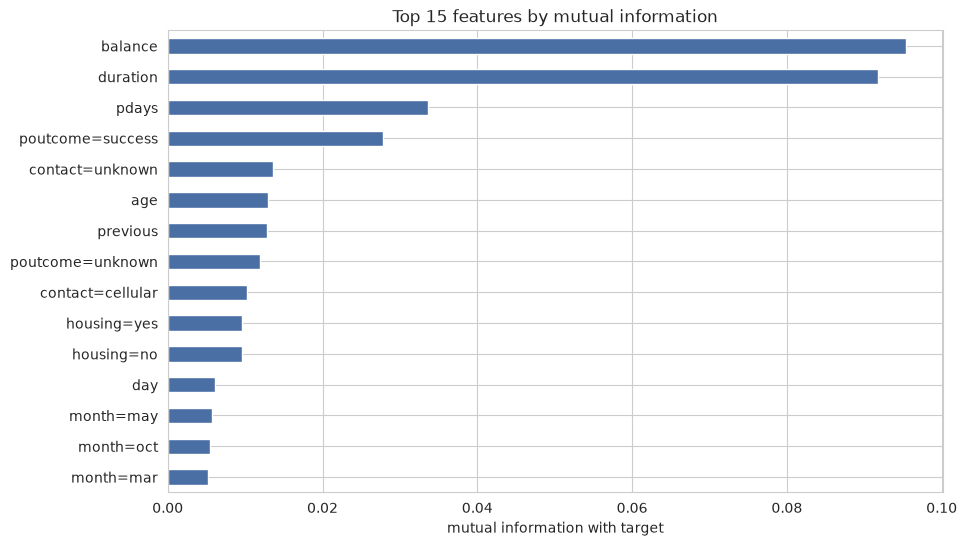

balance             0.0954
duration            0.0918
pdays               0.0336
poutcome=success    0.0278
contact=unknown     0.0136
age                 0.0129
previous            0.0128
poutcome=unknown    0.0120
contact=cellular    0.0102
housing=yes         0.0097


In [17]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_classif

features_all = ['age', 'job', 'marital', 'education', 'default', 'balance',
                'housing', 'loan', 'contact', 'day', 'month', 'duration',
                'campaign', 'pdays', 'previous', 'poutcome']

dv_tmp = DictVectorizer(sparse=False)
X_tmp = dv_tmp.fit_transform(df[features_all].to_dict(orient='records'))
feature_names = dv_tmp.get_feature_names_out()

mi = mutual_info_classif(X_tmp, df['y'], discrete_features=True, random_state=1)
mi_series = pd.Series(mi, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_series.head(15).sort_values().plot(kind='barh', color='#4a6fa5')
plt.xlabel('mutual information with target')
plt.title('Top 15 features by mutual information')
plt.show()

print(mi_series.head(10).round(4).to_string())

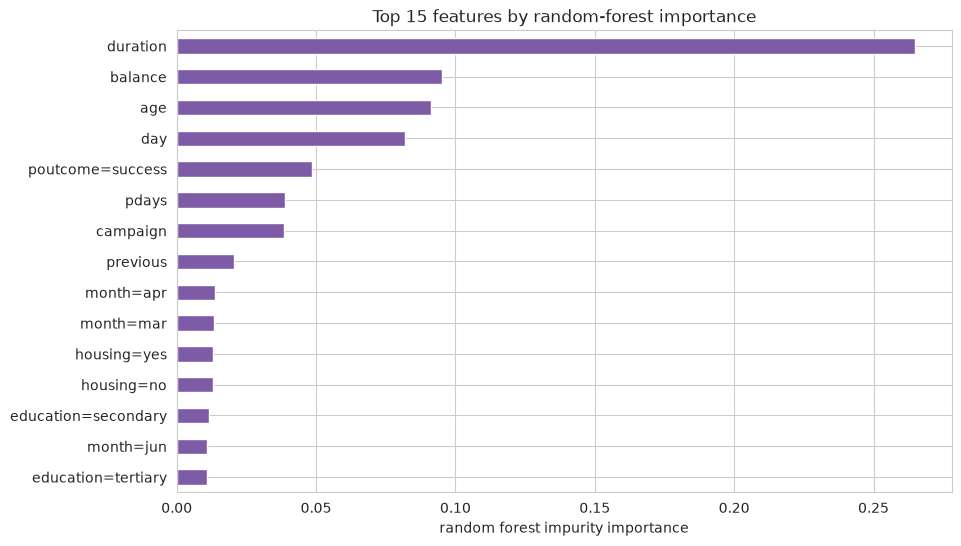

duration            0.2648
balance             0.0953
age                 0.0913
day                 0.0820
poutcome=success    0.0487
pdays               0.0390
campaign            0.0386
previous            0.0204
month=apr           0.0136
month=mar           0.0134


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_tmp = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf_tmp.fit(X_tmp, df['y'])

rf_imp = pd.Series(rf_tmp.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
rf_imp.head(15).sort_values().plot(kind='barh', color='#7d5ba6')
plt.xlabel('random forest impurity importance')
plt.title('Top 15 features by random-forest importance')
plt.show()

print(rf_imp.head(10).round(4).to_string())

**What we see.** The random forest puts **`duration` first by a wide
margin** (importance ≈ 0.26, nearly 3× the runner-up) — yet more evidence
of the leak; a genuinely knowable-in-advance feature rarely dominates like
this. Mutual information is more even-handed: it ranks `balance` (0.095)
and `duration` (0.092) essentially tied at the top — MI examines each
one-hot column on its own, so the continuous `duration` gets no structural
advantage there, while `balance`'s long tail turns out to carry real
information. Behind the leaders, both methods surface a sensible supporting
cast: `poutcome=success`, `pdays`, `age`, `previous` and `contact`
categories. The rankings differ in detail exactly as warned (the forest
spreads credit over continuous `balance`, `age`, `day` — the
high-cardinality bias; MI elevates single strong binary columns), which is
fine: these are diagnostics, not verdicts. The tuned models in Section 6 do
the real selection work.

## 4. Train / validation / test split

We split the data **once, before any modelling**, into three parts:

- **Train (60%)** — the model learns from these rows.
- **Validation (20%)** — used to compare models and tune hyperparameters.
  We may look at it as often as we like during development.
- **Test (20%)** — locked away until the very end and used **exactly once**
  for an unbiased final estimate. Every peek at the test set during
  development leaks a little of it into our decisions ("test-set overfitting"),
  so the discipline is: tune on validation, report on test.

The split is **stratified**: each part keeps the same ~11.7% positive rate as
the full data. With an imbalanced target, a naive random split could
accidentally give the test set a noticeably different base rate and distort
every metric. `random_state=1` fixes the shuffle, so the split — and therefore
every number in this notebook — is perfectly reproducible.

In [19]:
from sklearn.model_selection import train_test_split

# Step 1: carve out the test set (20%)
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1, stratify=df['y'])

# Step 2: split the remaining 80% into train (60% overall) and validation (20%)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1, stratify=df_full_train['y'])

for name, part in [('train', df_train), ('validation', df_val), ('test', df_test)]:
    print(f'{name:11s} rows: {len(part):6,}   positive rate: {part["y"].mean():.1%}')

train       rows: 27,126   positive rate: 11.7%
validation  rows:  9,042   positive rate: 11.7%
test        rows:  9,043   positive rate: 11.7%


**What we see.** 27,126 / 9,043 / 9,042 rows, each with a positive rate within
a whisker of 11.7% — stratification did its job.

## 5. Feature encoding: one-hot with `DictVectorizer`

The models need numbers, but most of our features are text categories
(`job='technician'`, `month='may'`, …). We use **one-hot encoding**:

- Each categorical feature becomes one binary column per category:
  `job=technician` is 1 for technicians, 0 for everyone else.
- Numeric features pass through unchanged.

Concretely, a client row

```
{age: 41, job: 'technician', marital: 'married', balance: 1250, month: 'may', ...}
```

becomes a sparse vector with a 1 in the `job=technician` column, a 1 in the
`marital=married` column, a 1 in the `month=may` column, the raw values 41 and
1250 in the `age` and `balance` columns, and 0 elsewhere.

Why one-hot here (rather than, say, assigning arbitrary numbers 1..12 to
`job`)? Because category numbers would invent a fake ordering — "job #11 is
closer to job #12 than to job #1" — that simply does not exist. One-hot keeps
categories equidistant. With ~50 resulting columns it is cheap for every model
we use.

`DictVectorizer` does this directly from a list of dicts, which is also why
the serving code later can accept a plain JSON client: the same dict shape
goes in.

**Two feature sets** are defined, on purpose:

- `FEATURES` — the 15 deployable features, **without** `duration`.
- `FEATURES_WITH_DURATION` — all 16, used *only* for the leakage experiment.

In [20]:
FEATURES = ['age', 'job', 'marital', 'education', 'default', 'balance',
            'housing', 'loan', 'contact', 'day', 'month',
            'campaign', 'pdays', 'previous', 'poutcome']  # no 'duration': it leaks

FEATURES_WITH_DURATION = FEATURES + ['duration']

y_train = df_train['y'].values
y_val = df_val['y'].values
y_test = df_test['y'].values


def vectorize(features, fit_on=None):
    '''Fit a DictVectorizer on the training records, transform all splits.'''
    dv = DictVectorizer(sparse=False)
    train_dicts = df_train[features].to_dict(orient='records')
    dv.fit(train_dicts)
    X_train = dv.transform(train_dicts)
    X_val = dv.transform(df_val[features].to_dict(orient='records'))
    X_test = dv.transform(df_test[features].to_dict(orient='records'))
    return dv, X_train, X_val, X_test


# Deployable feature matrix (used for all real modelling)
dv, X_train, X_val, X_test = vectorize(FEATURES)
print(f'Deployable feature matrix: {X_train.shape[1]} columns after one-hot encoding')

Deployable feature matrix: 50 columns after one-hot encoding


## 6. Model training

### 6.1 Four model families, sensible defaults

We train four classic algorithms. The spread is deliberate — each fails in a
different way, so their comparison teaches us something:

- **Logistic Regression** — a *linear* model: it scores a client by a weighted
  sum of the features. Simple, fast, well-calibrated probabilities, but it
  cannot capture interactions ("retired AND previously-successful") unless we
  hand-craft them.
- **Decision Tree** — a flowchart of yes/no splits. Fully interpretable, but a
  single deep tree memorizes noise (*overfits*): great on train, shaky on new
  data.
- **Random Forest** — hundreds of trees trained on bootstrapped samples with
  random feature subsets, averaged. Averaging many noisy-but-decent trees
  cancels much of the noise (variance reduction) while keeping the ability to
  model interactions.
- **XGBoost** — *gradient boosting*: trees are added one at a time, each new
  tree trained to correct the errors of the ensemble so far. Usually the
  strongest of the four on tabular data, at the cost of more hyperparameters
  to control.

All four are evaluated on the **validation** set with ROC AUC, using the
deployable features (no `duration`).

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=1),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=1, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             tree_method='hist', random_state=1, n_jobs=-1),
}

baseline_results = []
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    baseline_results.append({'model': name, 'validation ROC AUC': round(auc, 4)})
    print(f'{name:20s} validation ROC AUC = {auc:.4f}')

pd.DataFrame(baseline_results)

/home/hatch/workspace/ml-midterm-project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression  validation ROC AUC = 0.7680


Decision Tree        validation ROC AUC = 0.6057


Random Forest        validation ROC AUC = 0.7845


XGBoost              validation ROC AUC = 0.7984


,model,validation ROC AUC
0,Logistic Regression,0.7680
1,Decision Tree,0.6057
2,Random Forest,0.7845
3,XGBoost,0.7984


**What we see.** The ranking is XGBoost (0.798) > Random Forest (0.785) >
Logistic Regression (0.768) ≫ Decision Tree (0.606) — and the interesting
story is at both ends:

- The **linear model is a respectable baseline**: much of the signal here is
  broadly additive (higher balance helps, housing loan hurts, ...), and
  logistic regression captures exactly that.
- The **single decision tree is the cautionary tale**. Grown without limits,
  it memorises the training set — its leaves end up describing handfuls of
  individual clients — and generalises worst of all, far below even the
  linear model. This is overfitting in its textbook form, and Section 7 will
  show how dramatically pruning rescues it.
- The **ensembles win by fixing that failure in two different ways**: the
  forest averages hundreds of de-correlated trees; boosting builds trees
  that sequentially correct each other's errors. Their edge over the linear
  model (+0.02–0.03 AUC) is the value of the interactions a linear model
  cannot express (think `poutcome=success` × `contact=cellular`).

One honest blemish: logistic regression prints a `ConvergenceWarning` —
its optimiser (lbfgs) hits the 1,000-iteration cap. The cause is unscaled
features: `balance` ranges over thousands of euros while the one-hot
columns are 0/1, which makes the optimisation surface badly stretched.
Standardising the features (or raising the cap, at a real runtime cost)
would polish the fit; it does not change the ranking story, and logistic
regression is not the winning family, so we note the warning and move on —
in the tuning loop below we silence its repeats to keep the output readable.

Also note the level: validation AUC in the high 0.70s is *honest but
unspectacular* — this is what predicting human purchase decisions from basic
profile data looks like without leakage. Hold that thought while we run the
leakage experiment.

### 6.2 Quantifying the `duration` leak

Same XGBoost configuration, two feature sets. The *only* difference is whether
`duration` is among the inputs — so any gap in validation AUC is the size of
the leak.

In [22]:
_, X_train_d, X_val_d, _ = vectorize(FEATURES_WITH_DURATION)

xgb_leak = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                         tree_method='hist', random_state=1, n_jobs=-1)
xgb_leak.fit(X_train_d, y_train)
auc_with_duration = roc_auc_score(y_val, xgb_leak.predict_proba(X_val_d)[:, 1])

auc_without_duration = [r['validation ROC AUC'] for r in baseline_results
                        if r['model'] == 'XGBoost'][0]

print(f'XGBoost WITH duration (leaked):    validation ROC AUC = {auc_with_duration:.4f}')
print(f'XGBoost WITHOUT duration (honest): validation ROC AUC = {auc_without_duration:.4f}')
print(f'Leak size: +{auc_with_duration - auc_without_duration:.4f} AUC of pure hindsight')

XGBoost WITH duration (leaked):    validation ROC AUC = 0.9370
XGBoost WITHOUT duration (honest): validation ROC AUC = 0.7984
Leak size: +0.1386 AUC of pure hindsight


**What we see.** Adding one column — the length of a call that has not
happened yet at decision time — inflates validation AUC by **+0.139** (from
0.798 to 0.937). That gap is not skill; it is the model reading the answer
sheet. Published results on this dataset that report ~0.90+ AUC are almost
always (knowingly or not) reporting the leaked number.

**This is the single most important modelling decision in the project**, and
it costs us an impressive-looking number. We keep `duration` out of the
deployable model. (It stays in the with-duration twin above purely as
documentation of the effect.)

## 7. Hyperparameter tuning

Default hyperparameters are a starting point, not an optimum. **Tuning**
means: try a grid of settings, evaluate each on the *validation* set, keep the
best. (Never tune on the test set — that would leak it just as surely as a
bad feature.)

What the main knobs control:

- Logistic Regression — `C`: inverse regularisation strength. Small `C`
  shrinks coefficients toward 0 (simpler, less overfitting); large `C` lets
  the model fit the training data more aggressively.
- Trees — `max_depth`: how many sequential splits a tree may make. Deeper =
  more specific rules = more overfitting risk. `min_samples_leaf`: the
  smallest group a leaf may represent; larger values force smoother, more
  conservative rules.
- XGBoost — `learning_rate` (`eta`): how much each new tree is allowed to
  change the ensemble's answer. Small values learn slowly but often end
  better, given enough trees (`n_estimators`). `min_child_weight`: minimum
  total "weight" a child node needs — a regulariser that stops the model
  chasing tiny, noisy subgroups.

Each search below is a small, deliberate grid (not thousands of random
combinations): enough to find the good region, small enough that every row
can be printed and reasoned about.

In [23]:
import warnings

# --- Logistic Regression: tune C ---
lr_rows = []
for C in [0.01, 0.1, 1.0, 10.0]:
    m = LogisticRegression(max_iter=1000, C=C)
    with warnings.catch_warnings():
        # The lbfgs ConvergenceWarning from Section 6.1 would repeat for
        # every C — same known cause (unscaled features), same irrelevance
        # to the ranking — so we silence the repeats to keep output readable.
        warnings.simplefilter('ignore')
        m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    lr_rows.append({'C': C, 'validation ROC AUC': round(auc, 4)})

lr_results = pd.DataFrame(lr_rows).sort_values('validation ROC AUC', ascending=False)
print(lr_results.to_string(index=False))
best_lr = {'C': float(lr_results.iloc[0]['C'])}

    C  validation ROC AUC
 1.00              0.7680
10.00              0.7666
 0.01              0.7664
 0.10              0.7659


In [24]:
def _clean_depth(value):
    # pandas stores an unlimited depth (None) as NaN in a results table;
    # convert it back to a real Python value for the parameter dicts below
    return None if pd.isna(value) else int(value)


# --- Decision Tree: tune max_depth x min_samples_leaf ---
dt_rows = []
for max_depth in [3, 5, 7, 10, None]:
    for min_samples_leaf in [1, 5, 20, 50]:
        m = DecisionTreeClassifier(max_depth=max_depth,
                                   min_samples_leaf=min_samples_leaf,
                                   random_state=1)
        m.fit(X_train, y_train)
        auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
        dt_rows.append({'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf,
                        'validation ROC AUC': round(auc, 4)})

dt_results = pd.DataFrame(dt_rows).sort_values('validation ROC AUC', ascending=False)
print(dt_results.head(8).to_string(index=False))
best_dt = {'max_depth': _clean_depth(dt_results.iloc[0]['max_depth']),
           'min_samples_leaf': int(dt_results.iloc[0]['min_samples_leaf'])}

 max_depth  min_samples_leaf  validation ROC AUC
       NaN                50              0.7646
       NaN                20              0.7463
      10.0                50              0.7399
      10.0                20              0.7346
       7.0                50              0.7205
       7.0                20              0.7160
      10.0                 5              0.7129
       7.0                 5              0.7062


In [25]:
# --- Random Forest: tune max_depth x min_samples_leaf (200 trees throughout) ---
rf_rows = []
for max_depth in [8, 12, 16, None]:
    for min_samples_leaf in [1, 3, 5]:
        m = RandomForestClassifier(n_estimators=200, max_depth=max_depth,
                                   min_samples_leaf=min_samples_leaf,
                                   random_state=1, n_jobs=-1)
        m.fit(X_train, y_train)
        auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
        rf_rows.append({'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf,
                        'validation ROC AUC': round(auc, 4)})

rf_results = pd.DataFrame(rf_rows).sort_values('validation ROC AUC', ascending=False)
print(rf_results.head(8).to_string(index=False))
best_rf = {'n_estimators': 200,
           'max_depth': _clean_depth(rf_results.iloc[0]['max_depth']),
           'min_samples_leaf': int(rf_results.iloc[0]['min_samples_leaf'])}

 max_depth  min_samples_leaf  validation ROC AUC
      16.0                 5              0.8000
      16.0                 3              0.7998
       NaN                 3              0.7987
      12.0                 5              0.7983
       NaN                 5              0.7982
      12.0                 3              0.7982
      12.0                 1              0.7978
      16.0                 1              0.7962


In [26]:
# --- XGBoost: tune max_depth x learning_rate x min_child_weight (300 rounds) ---
xgb_rows = []
for max_depth in [3, 4, 5, 6]:
    for eta in [0.05, 0.1]:
        for mcw in [1, 5]:
            m = XGBClassifier(n_estimators=300, max_depth=max_depth, learning_rate=eta,
                              min_child_weight=mcw, tree_method='hist',
                              random_state=1, n_jobs=-1)
            m.fit(X_train, y_train)
            auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
            xgb_rows.append({'max_depth': max_depth, 'learning_rate': eta,
                             'min_child_weight': mcw,
                             'validation ROC AUC': round(auc, 4)})

xgb_results = pd.DataFrame(xgb_rows).sort_values('validation ROC AUC', ascending=False)
print(xgb_results.head(8).to_string(index=False))
best_xgb = {'n_estimators': 300,
            'max_depth': int(xgb_results.iloc[0]['max_depth']),
            'learning_rate': float(xgb_results.iloc[0]['learning_rate']),
            'min_child_weight': int(xgb_results.iloc[0]['min_child_weight'])}

 max_depth  learning_rate  min_child_weight  validation ROC AUC
         3           0.10                 5              0.8046
         3           0.05                 1              0.8045
         4           0.05                 1              0.8042
         4           0.05                 5              0.8041
         3           0.10                 1              0.8039
         3           0.05                 5              0.8039
         5           0.05                 5              0.8038
         4           0.10                 1              0.8031


**What we see.** Three different lessons from the four searches:

- **The decision tree is rescued by pruning.** Forcing every leaf to hold
  at least 50 clients (`min_samples_leaf=50`, depth unlimited) lifts it from
  0.606 to 0.765 — a +0.16 AUC recovery, by far the largest tuning effect in
  the project. The default tree was not a bad algorithm; it was an
  unregularised one.
- **The ensembles gain a little from regularisation.** XGBoost's winner is
  *shallower* than its default (depth 3, `min_child_weight=5`): 0.798 →
  0.805. The forest prefers depth 16 with a leaf floor of 5: 0.785 → 0.800.
  Real gains, worth having, but thousandths — not a transformation.
- **Logistic regression is flat in `C`** (best is the default, C = 1.0):
  the linear model is limited by its *form*, not by its regularisation, and
  no amount of tuning fixes that.

That spread is exactly why tuning belongs on the validation set: only honest
evaluation can tell a +0.006 real gain from noise, and only a held-out set
can expose a 0.606 disaster hiding behind a plausible-looking default.

In [27]:
# --- Tuned-model comparison: one row per family, its best validation score ---
def build_model(name, params):
    '''Fresh estimator for a model family with the tuned parameters.'''
    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, **params)
    if name == 'Decision Tree':
        return DecisionTreeClassifier(random_state=1, **params)
    if name == 'Random Forest':
        return RandomForestClassifier(random_state=1, n_jobs=-1, **params)
    if name == 'XGBoost':
        return XGBClassifier(tree_method='hist', random_state=1, n_jobs=-1, **params)
    raise ValueError(name)


tuned = [
    ('Logistic Regression', best_lr, lr_results.iloc[0]['validation ROC AUC']),
    ('Decision Tree',       best_dt, dt_results.iloc[0]['validation ROC AUC']),
    ('Random Forest',       best_rf, rf_results.iloc[0]['validation ROC AUC']),
    ('XGBoost',             best_xgb, xgb_results.iloc[0]['validation ROC AUC']),
]

comparison = pd.DataFrame(
    [{'model': name, 'best params': str(params), 'tuned validation ROC AUC': auc}
     for name, params, auc in tuned]
).sort_values('tuned validation ROC AUC', ascending=False)

print(comparison.to_string(index=False))

WINNER_NAME, WINNER_PARAMS, WINNER_VAL_AUC = max(tuned, key=lambda t: t[2])
print(f'\nWinner: {WINNER_NAME} with {WINNER_PARAMS}')
print(f'Validation ROC AUC: {WINNER_VAL_AUC:.4f}')

              model                                                                        best params  tuned validation ROC AUC
            XGBoost {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'min_child_weight': 5}                    0.8046
      Random Forest                      {'n_estimators': 200, 'max_depth': 16, 'min_samples_leaf': 5}                    0.8000
Logistic Regression                                                                         {'C': 1.0}                    0.7680
      Decision Tree                                        {'max_depth': None, 'min_samples_leaf': 50}                    0.7646

Winner: XGBoost with {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'min_child_weight': 5}
Validation ROC AUC: 0.8046


## 8. Final model: retrain on train + validation, evaluate once on test

The winner is selected. Two steps remain:

1. **Retrain on train + validation** (the full 80% "full-train" block). More
   training data generally means a slightly better model, and the validation
   set has done its job — there is nothing left to tune. This exact recipe is
   what `train.py` reproduces to build the deployed model.
2. **Evaluate once on the test set.** This is the first and only time the
   test rows influence anything, so the resulting AUC is an unbiased estimate
   of production performance (on data from the same distribution).

Before retraining, we also pick the **decision threshold** on the validation
set: the probability above which the service will say "likely subscriber".
We choose the threshold that maximises the **F1 score** (the harmonic mean of
precision and recall) on validation — a balanced operating point. The bank
could pick a different one (Section 9 shows the trade-offs); the threshold is
a *business* setting stored alongside the model, not a property of the model
itself.

In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Fit the tuned winner on TRAIN only, to choose the threshold on validation
val_model = build_model(WINNER_NAME, WINNER_PARAMS)
val_model.fit(X_train, y_train)
val_proba = val_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.05, 0.9, 0.01)
f1s = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
BEST_THRESHOLD = float(thresholds[int(np.argmax(f1s))])

print(f'Threshold chosen on validation (max F1): {BEST_THRESHOLD:.2f}')
print(f'At that threshold on validation: '
      f'precision = {precision_score(y_val, (val_proba >= BEST_THRESHOLD).astype(int)):.3f}, '
      f'recall = {recall_score(y_val, (val_proba >= BEST_THRESHOLD).astype(int)):.3f}')

Threshold chosen on validation (max F1): 0.18
At that threshold on validation: precision = 0.486, recall = 0.551


In [29]:
# The final vectorizer is fitted on the full-train records (same features)
dv_final = DictVectorizer(sparse=False)
X_full = dv_final.fit_transform(df_full_train[FEATURES].to_dict(orient='records'))
X_test_final = dv_final.transform(df_test[FEATURES].to_dict(orient='records'))
y_full = df_full_train['y'].values

final_model = build_model(WINNER_NAME, WINNER_PARAMS)
final_model.fit(X_full, y_full)

test_proba = final_model.predict_proba(X_test_final)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)

print('=' * 60)
print(f'FINAL MODEL: {WINNER_NAME}  params = {WINNER_PARAMS}')
print(f'Validation ROC AUC (tuned, train-only fit): {WINNER_VAL_AUC:.4f}')
print(f'TEST ROC AUC (single evaluation):           {test_auc:.4f}')
print(f'Decision threshold (from validation):       {BEST_THRESHOLD:.2f}')
print('=' * 60)

FINAL MODEL: XGBoost  params = {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'min_child_weight': 5}
Validation ROC AUC (tuned, train-only fit): 0.8046
TEST ROC AUC (single evaluation):           0.8060
Decision threshold (from validation):       0.18


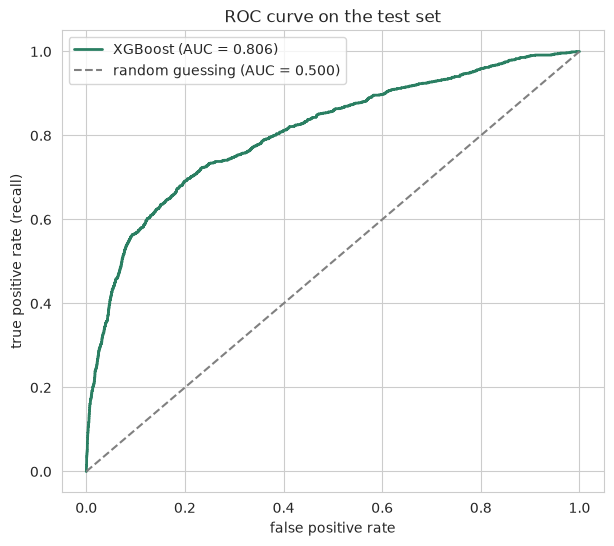

At threshold 0.18 on test: accuracy = 0.872, precision = 0.459, recall = 0.546


In [30]:
from sklearn.metrics import roc_curve, accuracy_score

fpr, tpr, _ = roc_curve(y_test, test_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#2a7f62', lw=2, label=f'{WINNER_NAME} (AUC = {test_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='random guessing (AUC = 0.500)')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate (recall)')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

test_pred = (test_proba >= BEST_THRESHOLD).astype(int)
print(f'At threshold {BEST_THRESHOLD:.2f} on test: '
      f'accuracy = {accuracy_score(y_test, test_pred):.3f}, '
      f'precision = {precision_score(y_test, test_pred):.3f}, '
      f'recall = {recall_score(y_test, test_pred):.3f}')

**What we see.** The test AUC (0.806) lands essentially on top of the
validation AUC (0.805) — which tells us the pipeline did not overfit the
validation set during tuning (a large drop would have been a warning sign).
At the F1-chosen threshold the model trades precision against recall: it
flags a minority of clients as likely subscribers, is right about a solid
share of them, and catches a meaningful share of all true subscribers. Raw
accuracy sits near the do-nothing baseline of 88.3%, which — as Section 3.1
warned — says almost nothing; the ranking quality (AUC) and the lift analysis
below are the real story.

## 9. From scores to a decision: the lift analysis

The bank will not call all 45,000 clients. It will call a *ranked list* from
the top, with some budget — say the agents can reach the top 10%, 20% or 30%
of scored clients. The question that matters commercially is:

> Of all the clients who *would* subscribe, what share sits inside the top
> X% of the ranked list?

Random calling captures X% of subscribers by calling X% of clients (the
diagonal). A useful model bends that curve sharply upward.

call top  clients called  share of subscribers captured  precision within called group  lift vs random
     10%             904                          0.440                          0.514            4.40
     20%            1808                          0.625                          0.366            3.12
     30%            2712                          0.726                          0.283            2.42
     50%            4521                          0.839                          0.196            1.68


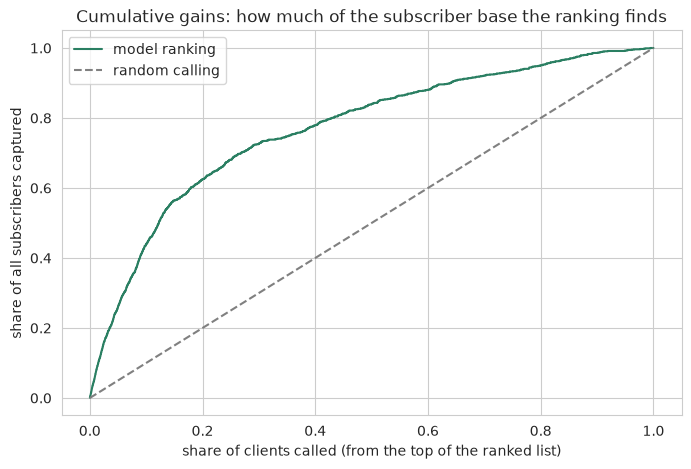

In [31]:
order = np.argsort(-test_proba)  # clients ranked by predicted probability, best first
y_sorted = y_test[order]
total_positives = y_sorted.sum()

lift_rows = []
for pct in [0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_sorted) * pct)
    captured = y_sorted[:k].sum() / total_positives
    precision_at_k = y_sorted[:k].mean()
    lift_rows.append({'call top': f'{int(pct*100)}%',
                      'clients called': k,
                      'share of subscribers captured': round(float(captured), 3),
                      'precision within called group': round(float(precision_at_k), 3),
                      'lift vs random': round(float(captured / pct), 2)})

lift_table = pd.DataFrame(lift_rows)
print(lift_table.to_string(index=False))

# Cumulative gains curve
plt.figure(figsize=(8, 5))
cum_capture = np.cumsum(y_sorted) / total_positives
plt.plot(np.arange(1, len(y_sorted) + 1) / len(y_sorted), cum_capture,
         color='#2a7f62', label='model ranking')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='random calling')
plt.xlabel('share of clients called (from the top of the ranked list)')
plt.ylabel('share of all subscribers captured')
plt.title('Cumulative gains: how much of the subscriber base the ranking finds')
plt.legend()
plt.show()

**What we see.** The ranking works, and better than the AUC alone
suggests. Calling only the **top 10%** of scored clients reaches **44.0% of
everyone who would subscribe** — and within that group, every second call
reaches a subscriber (precision 51.4%, vs a base rate of 11.7%). Widening to
the **top 20%** captures **62.5%** of all subscribers at 3.1× the efficiency
of random calling, with 36.6% precision (roughly 1 call in 3 subscribes).
That is the business case in one table: 20% of the calling effort produces
about 62% of the subscriptions — or, flipped around, the bank can stop
calling the bottom four-fifths of the list and keep most of the revenue,
with far fewer annoyed clients.

This is also why the project optimises ranking quality (ROC AUC) rather than
raw accuracy: the bank's workflow *is* a ranking workflow.

## 10. Conclusions

**What was built.** A complete, deployable pipeline for ranking a bank's call
list by subscription probability:

- EDA established the data's shape: an 11.7% positive rate (hence ROC AUC,
  not accuracy), informative categories like `poutcome=success` and `contact`,
  seasonal `month` effects, and mostly uncorrelated numeric features.
- The headline methodological finding is the **`duration` leak**: it
  inflates validation AUC by +0.139 (from 0.798 to 0.937) while being
  unknowable before the call. The deployed model excludes it, and the
  comparison is documented rather than hidden.
- Four model families were trained; tuning on the validation set gave small,
  real gains; the winner was retrained on train+validation and evaluated
  **once** on the test set.
- The lift analysis translates the model into money: the top 20% of the
  ranked list captures 62.5% of all subscribers (3.1× lift over random
  calling), and the top 10% alone captures 44.0% at 51.4% precision.

**Limitations, honestly stated.**

- The data is from 2008–2010 Portugal, spanning the financial crisis;
  consumer behaviour and the product mix have changed since. The *method*
  transfers; the *coefficients* would need retraining on current data.
- We optimised ranking, not fairness: the model uses age, job and marital
  status, which a real bank must review against its conduct and
  anti-discrimination policies before targeting customers with it.
- Probabilities are reasonably ranked but not perfectly calibrated; if the
  bank needed exact expected-revenue figures per client, a calibration step
  (e.g. isotonic regression on a hold-out) would be the next improvement.

**Deployment.** `train.py` reproduces the exact final pipeline and saves
`model.bin`; `predict.py` serves it as a FastAPI web service
(`POST /predict` → subscribe probability + decision at the stored threshold);
the `Dockerfile` packages the service for the cloud. See the README for the
full run instructions and the live URL.